# Join of the dastasets

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut

hd_df = pd.read_csv("../../data/processed/hd.csv")
lab_events_df = pd.read_csv("../../data/processed/lab_events.csv")
micro_bio_df = pd.read_csv("../../data/processed/microbio.csv")

# Make the join between processed datasets

joined_df = pd.merge(hd_df, lab_events_df, on='hadm_id', how='inner', suffixes=('_sx', '_rx'))
joined_df = pd.merge(
    joined_df,
    micro_bio_df,
    on=['subject_id', 'hadm_id'],
    how='inner',
    suffixes=('', '_micro')
)

# Drop all the lines that have a qc_flag = QC_WARN or QC_FAIL
joined_df = joined_df[joined_df['qc_flag'] == 'QC_OK']

# Drop ALL duplicate rows (keeps only unique rows)
joined_df = joined_df.drop_duplicates(keep=False).reset_index(drop=True)
joined_df

,subject_id,hadm_id,charttime_sx,icd_code,long_title,gender,age,charttime_rx,valuenum,ref_range_lower,...,charttime,spec_type_desc,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag
0,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,NaN,NaN,2151-05-24 02:30:00,26.0,22.0,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NaN,NaN,NaN,NaN,NaN,QC_OK
1,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,NaN,NaN,2151-05-24 02:30:00,7.4,8.4,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NaN,NaN,NaN,NaN,NaN,QC_OK
2,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,NaN,NaN,2151-05-24 02:30:00,104.0,96.0,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NaN,NaN,NaN,NaN,NaN,QC_OK
3,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,NaN,NaN,2151-05-24 02:30:00,1.4,0.5,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NaN,NaN,NaN,NaN,NaN,QC_OK
4,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,NaN,NaN,2151-05-24 02:30:00,114.0,70.0,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NaN,NaN,NaN,NaN,NaN,QC_OK
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2182066,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63.0,2128-02-27 09:23:00,4.7,4.0,...,2128-02-20 14:03:00,URINE,URINE CULTURE,KLEBSIELLA PNEUMONIAE,CEFEPIME,8,=,8.00,S,QC_OK
2182067,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63.0,2128-02-27 09:23:00,4.7,4.0,...,2128-02-20 14:03:00,URINE,URINE CULTURE,KLEBSIELLA PNEUMONIAE,MEROPENEM,<=0.25,<=,0.25,S,QC_OK
2182068,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63.0,2128-02-27 09:23:00,4.7,4.0,...,2128-02-20 14:03:00,URINE,URINE CULTURE,ENTEROCOCCUS SP.,AMPICILLIN,<=2,<=,2.00,S,QC_OK
2182069,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63.0,2128-02-27 09:23:00,4.7,4.0,...,2128-02-20 14:03:00,URINE,URINE CULTURE,ENTEROCOCCUS SP.,NITROFURANTOIN,<=16,<=,16.00,S,QC_OK


In [14]:
#Mask to find all the rows where 'valuenum' it outside the upper-lower range
mask_1 = (joined_df['valuenum'] < joined_df['ref_range_lower']) | (joined_df['valuenum'] > joined_df['ref_range_upper'])

# Mask to find all the rows where the flag is set to 0 (not abnormal)
mask_2 = (joined_df['flag'] == 0)

# Drops rows where mask_1 AND mask_2 are both True
joined_df = joined_df[~(mask_1 & mask_2)]

joined_df.drop(['ref_range_lower', 'ref_range_upper'], axis=1, inplace=True)

/var/folders/d3/b_pspz_d64lf1hwbztqr9l1r0000gn/T/ipykernel_47816/3572119086.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  joined_df.drop(['ref_range_lower', 'ref_range_upper'], axis=1, inplace=True)


## Age unification

In [15]:

# Calculate median age per icd_code
icd_stats = joined_df.groupby('icd_code')['age'].median().reset_index()
icd_stats.columns = ['icd_code', 'median_age']

# Merge median_age back to the original DataFrame
joined_df = joined_df.merge(icd_stats, on='icd_code', how='left')

# Fill missing age values with the median_age for that icd_code
joined_df['age'] = joined_df['age'].fillna(joined_df['median_age'])

# Drop the temporary median_age column
joined_df = joined_df.drop(columns=['median_age'])

joined_df



,subject_id,hadm_id,charttime_sx,icd_code,long_title,gender,age,charttime_rx,valuenum,flag,...,charttime,spec_type_desc,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag
0,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,NaN,52.0,2151-05-24 02:30:00,26.0,0,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NaN,NaN,NaN,NaN,NaN,QC_OK
1,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,NaN,52.0,2151-05-24 02:30:00,7.4,1,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NaN,NaN,NaN,NaN,NaN,QC_OK
2,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,NaN,52.0,2151-05-24 02:30:00,104.0,0,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NaN,NaN,NaN,NaN,NaN,QC_OK
3,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,NaN,52.0,2151-05-24 02:30:00,1.4,1,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NaN,NaN,NaN,NaN,NaN,QC_OK
4,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,NaN,52.0,2151-05-24 02:30:00,114.0,1,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NaN,NaN,NaN,NaN,NaN,QC_OK
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2181767,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63.0,2128-02-27 09:23:00,4.7,0,...,2128-02-20 14:03:00,URINE,URINE CULTURE,KLEBSIELLA PNEUMONIAE,CEFEPIME,8,=,8.00,S,QC_OK
2181768,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63.0,2128-02-27 09:23:00,4.7,0,...,2128-02-20 14:03:00,URINE,URINE CULTURE,KLEBSIELLA PNEUMONIAE,MEROPENEM,<=0.25,<=,0.25,S,QC_OK
2181769,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63.0,2128-02-27 09:23:00,4.7,0,...,2128-02-20 14:03:00,URINE,URINE CULTURE,ENTEROCOCCUS SP.,AMPICILLIN,<=2,<=,2.00,S,QC_OK
2181770,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63.0,2128-02-27 09:23:00,4.7,0,...,2128-02-20 14:03:00,URINE,URINE CULTURE,ENTEROCOCCUS SP.,NITROFURANTOIN,<=16,<=,16.00,S,QC_OK


## Correlation between the cols

In [16]:
# Getting the correlations
numeric_cols = du.get_numeric_cols(joined_df)
# Pearson correlation
joined_df[['age', 'valuenum', 'dilution_value']].corr("pearson")

,age,valuenum,dilution_value
age,1.000000,0.000531,0.047878
valuenum,0.000531,1.000000,-0.001017
dilution_value,0.047878,-0.001017,1.000000


In [17]:
# Kendall correlation
joined_df[['age', 'valuenum', 'dilution_value']].corr("kendall")

,age,valuenum,dilution_value
age,1.000000,0.002207,0.092397
valuenum,0.002207,1.000000,0.003071
dilution_value,0.092397,0.003071,1.000000


In [18]:
# Spearman correlation
joined_df[['age', 'valuenum', 'dilution_value']].corr("spearman")

,age,valuenum,dilution_value
age,1.000000,0.002982,0.115852
valuenum,0.002982,1.000000,0.004249
dilution_value,0.115852,0.004249,1.000000


In [19]:
# Abnormal flag ratio
abnormal_ratio = (
    joined_df
    .groupby(['subject_id', 'hadm_id'], as_index=False)['flag']
    .mean()
    .rename(columns={'flag': 'abnormal_flag_ratio'})
)
joined_df = joined_df.merge(abnormal_ratio, on=['subject_id', 'hadm_id'], how='left')

In [20]:
# Number of unique fluid types with abnormal results per admission
abnormal_mask = joined_df['flag'] == 1
fluid_abnormal = joined_df[abnormal_mask].groupby(['subject_id', 'hadm_id']).agg(
    abnormal_fluid_count=('fluid', 'nunique'),
    fluids_analyzed=('fluid', lambda x: ', '.join(x.unique()))
).reset_index()

# Add the columns to the joined_df
joined_df = joined_df.merge(fluid_abnormal, on=['subject_id', 'hadm_id'], how='left')

In [21]:
# Number of laboratory events per hadm_id
lab_events_count = joined_df.groupby('hadm_id').size()
lab_events_count

hadm_id
20029361     413
20060353     818
20072758    1701
20086741     590
20099221    1470
            ... 
29935379    1480
29961953    1968
29969310    3420
29970039     844
29976160     134
Length: 601, dtype: int64

## Patient risk profile

In [ ]:
# Build patient-level aggregates
base = joined_df[['subject_id', 'hadm_id', 'age', 'icd_code']]

org_count = (
    joined_df.groupby(['subject_id', 'hadm_id'])['org_name']
    .nunique()
    .reset_index(name='unique_organisms_count')
)

ab_count = (
    joined_df.groupby(['subject_id', 'hadm_id'])['ab_name']
    .nunique()
    .reset_index(name='unique_antibiotics_count')
)

resistance_stats = (
    joined_df[joined_df['interpretation'] == 'R']
    .dropna(subset=['ab_name'])
    .groupby(['subject_id', 'hadm_id'], as_index=False)
    .agg(
        resistant_organism_count=('org_name', 'nunique'),
        resistant_antibiotic_count=('ab_name', 'nunique')
    )
)

abnormal_ratio = (
    joined_df.groupby(['subject_id', 'hadm_id'])['flag']
    .mean()
    .reset_index(name='abnormal_flag_ratio')
)

abnormal_fluids = (
    joined_df[joined_df['flag'] == 1]
    .groupby(['subject_id', 'hadm_id'])
    .agg(
        abnormal_fluid_count=('fluid', 'nunique'),
        fluids_analyzed=('fluid', lambda x: ', '.join(sorted(x.unique())))
    )
    .reset_index()
)

# Assemble risk profile
risk_profile = (
    base.merge(org_count, on=['subject_id', 'hadm_id'], how='left')
        .merge(ab_count, on=['subject_id', 'hadm_id'], how='left')
        .merge(resistance_stats, on=['subject_id', 'hadm_id'], how='left')
        .merge(abnormal_ratio, on=['subject_id', 'hadm_id'], how='left')
        .merge(abnormal_fluids, on=['subject_id', 'hadm_id'], how='left')
)


risk_profile = risk_profile.drop_duplicates(['subject_id', 'hadm_id'])
risk_profile.to_csv("../../data/profiles/risk_profile.csv")

risk_profile

,subject_id,hadm_id,age,icd_code,unique_organisms_count,unique_antibiotics_count,resistant_organism_count,resistant_antibiotic_count,abnormal_flag_ratio,abnormal_fluid_count,fluids_analyzed
0,10063534,26199018,52.0,I31,1,0,NaN,NaN,0.540698,2,"Blood, Other Body Fluid"
172,10089244,29469323,63.0,I33,1,0,NaN,NaN,0.375194,2,"Blood, Urine"
817,10094805,21370539,59.0,I47,1,0,NaN,NaN,0.397196,2,"Blood, Urine"
1459,10104308,24307783,74.0,I21,1,10,1.0,1.0,0.422961,2,"Blood, Urine"
4769,10108435,23333218,80.0,I50,1,9,1.0,4.0,0.430769,2,"Blood, Urine"
...,...,...,...,...,...,...,...,...,...,...,...
2166717,19966553,27576329,88.0,I21,1,9,1.0,3.0,0.485356,1,Blood
2168868,19990821,27777812,70.0,I21,2,6,1.0,1.0,0.394689,2,"Blood, Urine"
2176512,19992875,20870047,37.0,I31,2,1,NaN,NaN,0.397674,3,"Blood, Other Body Fluid, Urine"
2177372,19997293,28847872,91.0,I44,1,0,NaN,NaN,0.431915,2,"Blood, Urine"


## Treatment Response Profiles

In [23]:
intermediate_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'I']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

resistant_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'R']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

sensitive_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'S']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

treatment_profile = (
    joined_df[
        joined_df['ab_name'].notna() & joined_df['interpretation'].notna()
    ]
    .groupby(['subject_id', 'hadm_id', 'interpretation'])
    .agg(
        organism_count=('org_name', 'nunique'),
        antibiotic_count=('ab_name', 'nunique')
    )
    .unstack(fill_value=0)
)

treatment_profile.columns = [
    f"{metric}_{label.lower()}"
    for metric, label in treatment_profile.columns
]

treatment_profile = treatment_profile.reset_index()
treatment_profile.to_csv("../../data/profiles/treatment_profile.csv")

treatment_profile


,subject_id,hadm_id,organism_count_i,organism_count_r,organism_count_s,antibiotic_count_i,antibiotic_count_r,antibiotic_count_s
0,10104308,24307783,0,1,1,0,1,9
1,10108435,23333218,0,1,1,0,4,5
2,10109085,25661234,0,0,1,0,0,8
3,10124346,24026336,0,1,1,0,1,10
4,10169726,22012406,0,0,1,0,0,7
...,...,...,...,...,...,...,...,...
374,19961611,25180816,0,0,1,0,0,6
375,19966553,27576329,0,1,1,0,3,6
376,19990821,27777812,0,1,1,0,1,5
377,19992875,20870047,0,0,1,0,0,1


## Visual exploration
The following plots give a quick overview of age distribution in the cohort, the tests with the highest abnormal rates, and how resistance relates to antibiotic coverage.

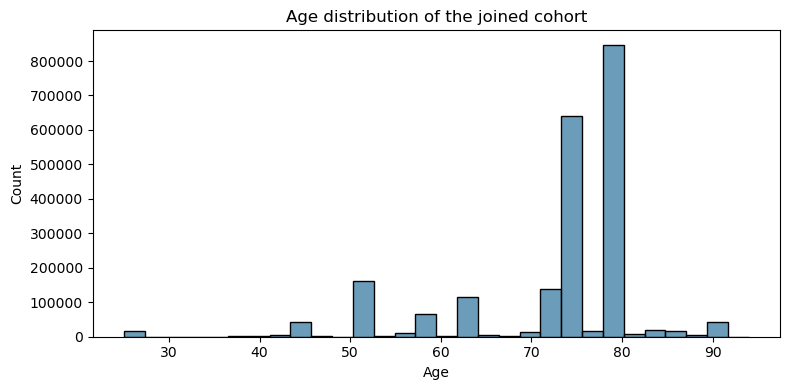

In [24]:
plt.figure(figsize=(8, 4))
sns.histplot(joined_df['age'].dropna(), bins=30, color='#3A7CA5')
plt.title('Age distribution of the joined cohort')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()